In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_pre
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobile_pre
import os, math, numpy as np


In [2]:
TRAIN_DIR = r"C:Downloads/AmirMalik_Portfolio/AmirMalik_portfolio/New_Dataset-20260129T064450Z-3-001/New_Dataset/train"
VAL_DIR   = r"C:Downloads/AmirMalik_Portfolio/AmirMalik_portfolio/New_Dataset-20260129T064450Z-3-001/New_Dataset/val"

IMG_SIZE = (224,224)
BATCH_SIZE = 32


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print(class_names)


Found 7488 files belonging to 3 classes.
Found 1498 files belonging to 3 classes.
['Early_blight', 'Healthy', 'Late_blight']


In [4]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.apply(tf.data.experimental.ignore_errors()).repeat().prefetch(AUTOTUNE)
val_ds   = val_ds.apply(tf.data.experimental.ignore_errors()).repeat().prefetch(AUTOTUNE)


Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.


In [5]:
def count_images(folder):
    total = 0
    for root,_,files in os.walk(folder):
        total += len([f for f in files if f.lower().endswith((".jpg",".png",".jpeg"))])
    return total

steps_train = math.ceil(count_images(TRAIN_DIR)/BATCH_SIZE)
steps_val   = math.ceil(count_images(VAL_DIR)/BATCH_SIZE)

print("Steps:", steps_train, steps_val)


Steps: 234 47


In [6]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.25),
    layers.RandomContrast(0.2),
])


In [7]:
inputs = keras.Input(shape=(224,224,3))
aug = augment(inputs)


In [8]:
resnet = ResNet50(include_top=False, weights="imagenet")
resnet.trainable = False

x_res = resnet_pre(aug)
r = resnet(x_res, training=False)
r = layers.GlobalAveragePooling2D()(r)

r = layers.Dense(512, activation="relu")(r)
r = layers.BatchNormalization()(r)
r = layers.Dropout(0.3)(r)

r = layers.Dense(256, activation="relu")(r)


In [9]:
mobilenet = MobileNetV2(include_top=False, weights="imagenet")
mobilenet.trainable = False

x_mob = mobile_pre(aug)
m = mobilenet(x_mob, training=False)
m = layers.GlobalAveragePooling2D()(m)

m = layers.Dense(256, activation="relu")(m)
m = layers.BatchNormalization()(m)
m = layers.Dropout(0.3)(m)

m = layers.Dense(128, activation="relu")(m)


C:\Users\amirm\AppData\Local\Temp\ipykernel_6752\1813484829.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet = MobileNetV2(include_top=False, weights="imagenet")


In [10]:
c = layers.Rescaling(1./255)(aug)

c = layers.Conv2D(32,3,padding="same",activation="relu")(c)
c = layers.BatchNormalization()(c)
c = layers.Conv2D(32,3,padding="same",activation="relu")(c)
c = layers.MaxPooling2D()(c)

c = layers.Conv2D(64,3,padding="same",activation="relu")(c)
c = layers.BatchNormalization()(c)
c = layers.Conv2D(64,3,padding="same",activation="relu")(c)
c = layers.MaxPooling2D()(c)

c = layers.Conv2D(128,3,padding="same",activation="relu")(c)
c = layers.BatchNormalization()(c)
c = layers.MaxPooling2D()(c)

c = layers.Conv2D(256,3,padding="same",activation="relu")(c)
c = layers.GlobalAveragePooling2D()(c)

c = layers.Dense(256, activation="relu")(c)
c = layers.Dropout(0.3)(c)


In [11]:
combined = layers.concatenate([r, m, c])

z = layers.Dense(512, activation="relu")(combined)
z = layers.BatchNormalization()(z)
z = layers.Dropout(0.5)(z)

z = layers.Dense(256, activation="relu")(z)
z = layers.BatchNormalization()(z)
z = layers.Dropout(0.4)(z)

outputs = layers.Dense(num_classes, activation="softmax")(z)

model = keras.Model(inputs, outputs)
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 224, 224, 3)       │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling (Rescaling)         │ (None, 224, 224, 3)       │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 224, 224, 32)      │             896 │ rescaling[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 224, 224, 32)      │             128 │ conv2d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 224, 224, 32)      │           9,248 │ batch_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 112, 112, 32)      │               0 │ conv2d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 112, 112, 64)      │          18,496 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 112, 112, 64)      │             256 │ conv2d_2[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 112, 112, 64)      │          36,928 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ true_divide (TrueDivide)      │ (None, 224, 224, 3)       │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 28,354,659 (108.16 MB)

 Trainable params: 2,505,443 (9.56 MB)

 Non-trainable params: 25,849,216 (98.61 MB)

In [12]:
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [13]:
from sklearn.utils.class_weight import compute_class_weight

labels=[]
for i,c in enumerate(class_names):
    labels += [i]*len(os.listdir(os.path.join(TRAIN_DIR,c)))

cw = compute_class_weight("balanced", classes=np.unique(labels), y=labels)
class_weights = dict(enumerate(cw))

print(class_weights)


{0: np.float64(0.9995995194233079), 1: np.float64(1.0008019246190858), 2: np.float64(0.9995995194233079)}


In [13]:
checkpoint_cb = keras.callbacks.ModelCheckpoint(
    "best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

lr_cb = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=3,
    verbose=1
)

early_cb = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=6,
    restore_best_weights=True
)


In [18]:
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    steps_per_epoch=steps_train,
    validation_steps=steps_val,
    class_weight=class_weights,
    callbacks=[checkpoint_cb, lr_cb, early_cb]
)


Epoch 1/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7394 - loss: 0.6953 
Epoch 1: val_accuracy improved from None to 0.78319, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
234/234 ━━━━━━━━━━━━━━━━━━━━ 2657s 11s/step - accuracy: 0.8360 - loss: 0.4585 - val_accuracy: 0.7832 - val_loss: 0.8021 - learning_rate: 0.0010
Epoch 2/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9210 - loss: 0.2370
Epoch 2: val_accuracy improved from 0.78319 to 0.94797, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
234/234 ━━━━━━━━━━━━━━━━━━━━ 1370s 6s/step - accuracy: 0.9236 - loss: 0.2212 - val_accuracy: 0.9480 - val_loss: 0.1414 - learning_rate: 0.0010
Epoch 3/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9427 - loss: 0.1655
Epoch 3: val_accuracy improved from 0.94797 to 0.95330, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
234/234 ━━━━━━━━━━━━━━━━━━━━ 1358s 6

KeyboardInterrupt: 

In [ ]:
#Fine Tuning 

# Unfreeze ALL layers except BatchNorm (safer fine-tuning)
for layer in model.layers:
    if not isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = True

print(" All trainable layers unfrozen")

# Recompile with very small learning rate
model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(" Model recompiled")

# Fine-tune training
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint_cb, lr_cb, early_cb]
)

print(" Fine-tuning complete")


 All trainable layers unfrozen
 Model recompiled
Epoch 1/10
      3/Unknown 163s 9s/step - accuracy: 0.3472 - loss: 1.7345 

In [14]:
model = keras.models.load_model("best_model.keras")

print(" Model loaded")
model.summary()


 Model loaded


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 224, 224, 3)       │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling (Rescaling)         │ (None, 224, 224, 3)       │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 224, 224, 32)      │             896 │ rescaling[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 224, 224, 32)      │             128 │ conv2d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 224, 224, 32)      │           9,248 │ batch_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 112, 112, 32)      │               0 │ conv2d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 112, 112, 64)      │          18,496 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 112, 112, 64)      │             256 │ conv2d_2[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 112, 112, 64)      │          36,928 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ true_divide (TrueDivide)      │ (None, 224, 224, 3)       │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 33,365,547 (127.28 MB)

 Trainable params: 2,505,443 (9.56 MB)

 Non-trainable params: 25,849,216 (98.61 MB)

 Optimizer params: 5,010,888 (19.12 MB)

In [16]:
from tensorflow.keras.utils import load_img, img_to_array

img_path = r"Downloads/healthy4.jpg"

img = load_img(img_path, target_size=(224,224))
arr = img_to_array(img)
arr = np.expand_dims(arr, axis=0)

pred = model.predict(arr, verbose=0)
pred_class = np.argmax(pred)

print("Prediction:", class_names[pred_class])
print("Confidence:", float(np.max(pred)))


Prediction: Healthy
Confidence: 0.9786732792854309


In [17]:
import random

def predict_random_per_class(model, val_dir, class_names, per_class=50):

    total = 0
    correct = 0

    for class_idx, class_name in enumerate(class_names):

        class_path = os.path.join(val_dir, class_name)

        images = [f for f in os.listdir(class_path)
                  if f.lower().endswith((".jpg",".png",".jpeg"))]

        samples = random.sample(images, min(per_class, len(images)))

        for img_name in samples:

            path = os.path.join(class_path, img_name)

            img = load_img(path, target_size=(224,224))
            arr = img_to_array(img)
            arr = np.expand_dims(arr, axis=0)

            pred = model.predict(arr, verbose=0)
            pred_idx = np.argmax(pred)

            if pred_idx == class_idx:
                correct += 1

            total += 1

    acc = correct / total
    print("\n Random Sample Accuracy:", round(acc*100,2), "%")

predict_random_per_class(model, VAL_DIR, class_names)



 Random Sample Accuracy: 92.0 %


In [18]:
class_names = ['Early_blight','Healthy','Late_blight']  # match your training order

predict_random_per_class(
    model,
    VAL_DIR,
    class_names,
    per_class=10
)



 Random Sample Accuracy: 93.33 %


In [19]:
from PIL import Image
import os

bad_files = []

for root, _, files in os.walk(VAL_DIR):
    for name in files:
        path = os.path.join(root, name)

        try:
            img = Image.open(path)
            img.verify()  # check corruption
        except:
            bad_files.append(path)

print("Broken images found:", len(bad_files))

for f in bad_files:
    print("Deleting:", f)
    os.remove(f)

print(" Corrupted images removed")


Broken images found: 0
 Corrupted images removed


In [20]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(224,224),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("Total batches:", len(val_ds))
print("Estimated total images:", len(val_ds) * 32)


Found 1498 files belonging to 3 classes.
Total batches: 47
Estimated total images: 1504


In [21]:
y_true = []
y_pred = []

for batch_idx, (images, labels) in enumerate(val_ds):

    preds = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

    print(f"Batch {batch_idx+1}/{len(val_ds)} done")

print(" Evaluation complete")
print("Total evaluated:", len(y_true))


Batch 1/47 done
Batch 2/47 done
Batch 3/47 done
Batch 4/47 done
Batch 5/47 done
Batch 6/47 done
Batch 7/47 done
Batch 8/47 done
Batch 9/47 done
Batch 10/47 done
Batch 11/47 done
Batch 12/47 done
Batch 13/47 done
Batch 14/47 done
Batch 15/47 done
Batch 16/47 done
Batch 17/47 done
Batch 18/47 done
Batch 19/47 done
Batch 20/47 done
Batch 21/47 done
Batch 22/47 done
Batch 23/47 done
Batch 24/47 done
Batch 25/47 done
Batch 26/47 done
Batch 27/47 done
Batch 28/47 done
Batch 29/47 done
Batch 30/47 done
Batch 31/47 done
Batch 32/47 done
Batch 33/47 done
Batch 34/47 done
Batch 35/47 done
Batch 36/47 done
Batch 37/47 done
Batch 38/47 done
Batch 39/47 done
Batch 40/47 done
Batch 41/47 done
Batch 42/47 done
Batch 43/47 done
Batch 44/47 done
Batch 45/47 done
Batch 46/47 done
Batch 47/47 done
 Evaluation complete
Total evaluated: 1498


In [22]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

Early_blight       0.95      0.93      0.94       500
     Healthy       0.97      1.00      0.98       499
 Late_blight       0.94      0.94      0.94       499

    accuracy                           0.96      1498
   macro avg       0.96      0.96      0.96      1498
weighted avg       0.96      0.96      0.96      1498



[[466   7  27]
 [  0 498   1]
 [ 23   9 467]]


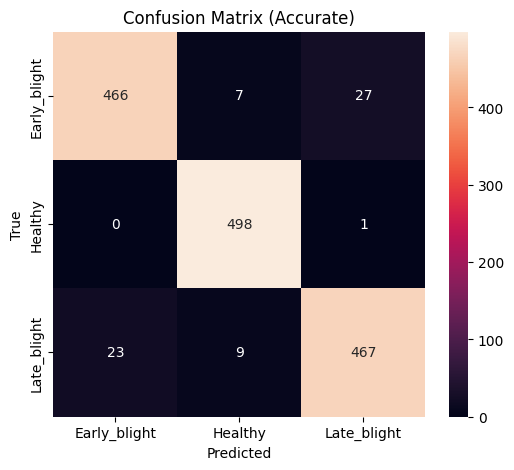

In [23]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

print(cm)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Accurate)")
plt.show()

